Frozen test, explanations and failure analysis

Day 8. The frozen model M1 (equal-weight composite with literature signs) is applied once to the test period
(2025-01-31 onward). Nothing here is used to choose or change a model.
Other models on test are shown for transparency only (post-hoc, not selected).
Outputs: `reports/test_results.csv`, `reports/test_results_all_models.csv` and charts 09-15 in `reports/figures/`.

## Setup

In [1]:
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# src is one folder up from notebooks, so add that folder so the import works
sys.path.append("..")
from src.evaluate import rank_ic_by_date, evaluate_score, bucket_returns, top_k_returns, bootstrap_mean_ci
from src.models import (prepare_model_data, add_standard_interactions, build_model_registry, make_lightgbm,
                        m1_fit_predict, COMPOSITE_PRIORS)

MODEL_TABLE_PATH = "../data/processed/model_table.csv"
BENCHMARK_EW_PATH = "../data/processed/benchmark_ew.csv"
BENCHMARK_NIFTY_PATH = "../data/processed/benchmark_nifty.csv"
FROZEN_PATH = "../reports/frozen_model.json"
WALK_FORWARD_STEPS_PATH = "../reports/walk_forward_steps.csv"
TEST_RESULTS_PATH = "../reports/test_results.csv"
ALL_MODELS_PATH = "../reports/test_results_all_models.csv"
FIGURE_FOLDER = "../reports/figures/"

TEST_START = pd.Timestamp("2025-01-31")

C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load data and the frozen model

In [2]:
with open(FROZEN_PATH) as frozen_file:
    frozen = json.load(frozen_file)

print("frozen model:", frozen["chosen_model"], "-", frozen["label"])
print("frozen features:", frozen["feature_cols"])
print("frozen signs:", frozen["composite_priors"])

model_table = pd.read_csv(MODEL_TABLE_PATH, parse_dates=["Date"])

# warm-up rows are never used. rows without a label are kept (the latest date has none)
df_all, feature_cols, state_z_cols = prepare_model_data(model_table, ["train", "validation", "test"], False)

# same interaction columns and model definitions as notebook 06 (both come from src/models.py)
df_all, feature_x_feature_cols, feature_x_state_cols = add_standard_interactions(df_all)
model_registry = build_model_registry(feature_cols, feature_x_feature_cols, feature_x_state_cols)
tree_cols = model_registry["M9"]["features"]

print()
print("rows:", len(df_all), "| dates:", df_all["Date"].nunique(), "| last date:", df_all["Date"].max().date())
print("rows per split:")
print(df_all.groupby("split").size())

frozen model: M1 - equal-weight composite of 7 features with a prior
frozen features: ['mom_1m_n', 'mom_6_1_n', 'mom_12_1_n', 'retvol_21d_n', 'retvol_63d_n', 'maxret_21d_n', 'idiovol_252d_n']
frozen signs: {'mom_1m_n': -1, 'mom_6_1_n': 1, 'mom_12_1_n': 1, 'retvol_21d_n': -1, 'retvol_63d_n': -1, 'maxret_21d_n': -1, 'idiovol_252d_n': -1}

rows: 2400 | dates: 80 | last date: 2026-08-31
rows per split:
split
test           600
train         1440
validation     360
dtype: int64


## Benchmarks

In [3]:
benchmark_ew = pd.read_csv(BENCHMARK_EW_PATH, parse_dates=["Date"]).set_index("Date")["fwd_1m"]

# the nifty file was saved on day 5
try:
    benchmark_nifty = pd.read_csv(BENCHMARK_NIFTY_PATH, parse_dates=["Date"]).set_index("Date")["fwd_1m"]
    print("nifty benchmark loaded, months:", len(benchmark_nifty))
except Exception:
    benchmark_nifty = None
    print("WARNING: no nifty file, using equal-weight only")
print("equal-weight benchmark months:", len(benchmark_ew))

nifty benchmark loaded, months: 92
equal-weight benchmark months: 92


## Part A: frozen test (M1, run once)

In [4]:
# test rows with a 1-month label, from 2025-01-31 onward
test_df = df_all[(df_all["split"] == "test") & df_all["has_label_1m"] & (df_all["Date"] >= TEST_START)].copy()

# M1 has nothing to fit, so the training table is empty. it only needs the features and the frozen signs.
empty_train = df_all.iloc[0:0]
test_df["score"] = m1_fit_predict(empty_train, test_df, frozen["feature_cols"], {})

print("test months:", test_df["Date"].nunique(), "(expected 19)")
print("first test date:", test_df["Date"].min().date(), "| last test date:", test_df["Date"].max().date())
print("test rows:", len(test_df))

test months: 19 (expected 19)
first test date: 2025-01-31 | last test date: 2026-07-31
test rows: 570


In [5]:
# one function that turns a table of scores into every test metric
def summarize_on_test(scored_df):
    stats = evaluate_score(scored_df, "score", k_list=[5, 10], benchmark_ew=benchmark_ew, benchmark_nifty=benchmark_nifty)

    # bootstrap 90% interval of the mean ic
    ic_series = rank_ic_by_date(scored_df, "score")
    ci_low, ci_high = bootstrap_mean_ci(ic_series, n_boot=2000, seed=42, ci_level=90)
    stats["ic_ci_low"] = ci_low
    stats["ic_ci_high"] = ci_high

    # 3-month robustness: skip dates that have no 3-month label yet (labels overlap, so no t-stat here)
    with_3m_label = scored_df[scored_df["fwd_3m"].notna()]
    ic_3m = rank_ic_by_date(with_3m_label, "score", "fwd_3m")
    stats["mean_ic_3m"] = ic_3m.mean()
    stats["n_months_3m"] = len(ic_3m)
    return stats

m1_test_stats = summarize_on_test(test_df)
m1_test_ic = rank_ic_by_date(test_df, "score")

for key in m1_test_stats:
    print(key.ljust(22), round(float(m1_test_stats[key]), 4))

mean_ic                -0.0899
std_ic                 0.2538
icir                   -0.3542
t_stat                 -1.544
pct_positive           42.1053
n_months               19.0
monotonicity           -0.9
bucket_1               0.0213
bucket_2               0.0079
bucket_3               0.0127
bucket_4               0.0027
bucket_5               0.0021
long_short_mean        -0.0192
long_short_sharpe      -1.436
top5_mean_return       0.0025
top5_excess_ew         -0.0068
top5_sharpe_ew         -0.9175
top5_hit_rate_ew       36.8421
top5_max_drawdown      -0.1328
top5_excess_nifty      0.0003
top5_sharpe_nifty      0.0449
top5_hit_rate_nifty    52.6316
top5_turnover          0.6111
top10_mean_return      0.0049
top10_excess_ew        -0.0044
top10_sharpe_ew        -0.853
top10_hit_rate_ew      42.1053
top10_max_drawdown     -0.1252
top10_excess_nifty     0.0028
top10_sharpe_nifty     0.4842
top10_hit_rate_nifty   57.8947
top10_turnover         0.4056
ic_ci_low              -0.1837


In [6]:
# save one row per metric
results_rows = []
for key in m1_test_stats:
    results_rows.append({"metric": key, "value": float(m1_test_stats[key])})
test_results = pd.DataFrame(results_rows)
test_results.to_csv(TEST_RESULTS_PATH, index=False)
print("saved", TEST_RESULTS_PATH)
print()

print("=" * 90)
print("frozen model M1 on unseen test data: mean ic =", round(m1_test_stats["mean_ic"], 4),
      "| 90% ci [", round(m1_test_stats["ic_ci_low"], 4), ",", round(m1_test_stats["ic_ci_high"], 4), "]",
      "| icir =", round(m1_test_stats["icir"], 3),
      "| t-stat =", round(m1_test_stats["t_stat"], 2),
      "| months =", m1_test_stats["n_months"])
print("=" * 90)

saved ../reports/test_results.csv

frozen model M1 on unseen test data: mean ic = -0.0899 | 90% ci [ -0.1837 , 0.0035 ] | icir = -0.354 | t-stat = -1.54 | months = 19


## Part B: other models on test (post-hoc comparison, not selected)

In [7]:
# hyperparameters "chosen for 2024" come from the walk-forward step log saved by notebook 06
walk_forward_steps = pd.read_csv(WALK_FORWARD_STEPS_PATH)

other_specs = {
    "M3": model_registry["M3"],
    "M7": model_registry["M7"],
    "M9": model_registry["M9"],
}

params_2024 = {}
for name in other_specs:
    rows_2024 = walk_forward_steps[(walk_forward_steps["model"] == name) & (walk_forward_steps["year"] == 2024)]
    params_2024[name] = json.loads(rows_2024["params"].iloc[0])
    print(name, "params chosen for 2024:", params_2024[name])

M3 params chosen for 2024: {'alpha': 0.01, 'l1_ratio': 0.8}
M7 params chosen for 2024: {'alpha': 0.001, 'l1_ratio': 0.2}
M9 params chosen for 2024: {'num_leaves': 7, 'learning_rate': 0.03, 'n_estimators': 200, 'min_child_samples': 30, 'subsample': 0.8, 'colsample_bytree': 0.8, 'random_state': 42}


In [8]:
# refit twice: train before 2025 -> predict 2025, train before 2026 -> predict 2026 (labelled months only)
labelled_df = df_all[df_all["has_label_1m"]]
refit_log = []
other_scored = {}

for name in other_specs:
    spec = other_specs[name]
    pieces = []
    for year in [2025, 2026]:
        year_start = pd.Timestamp(str(year) + "-01-01")
        next_year_start = pd.Timestamp(str(year + 1) + "-01-01")

        train_part = labelled_df[labelled_df["Date"] < year_start]
        predict_part = labelled_df[(labelled_df["Date"] >= year_start) & (labelled_df["Date"] < next_year_start)].copy()

        # no lookahead: training data must end before the first prediction date
        assert train_part["Date"].max() < predict_part["Date"].min(), "training reaches into the prediction year"

        predict_part["score"] = spec["function"](train_part, predict_part, spec["features"], params_2024[name])
        pieces.append(predict_part)

        refit_log.append({"model": name, "year": year, "n_train": len(train_part),
                          "max_train_date": train_part["Date"].max(),
                          "min_predict_date": predict_part["Date"].min(), "n_predict": len(predict_part)})

    other_scored[name] = pd.concat(pieces)

refit_log = pd.DataFrame(refit_log)
print(refit_log.to_string(index=False))

model  year  n_train max_train_date min_predict_date  n_predict
   M3  2025     1800     2024-12-31       2025-01-31        360
   M3  2026     2160     2025-12-31       2026-01-30        210
   M7  2025     1800     2024-12-31       2025-01-31        360
   M7  2026     2160     2025-12-31       2026-01-30        210
   M9  2025     1800     2024-12-31       2025-01-31        360
   M9  2026     2160     2025-12-31       2026-01-30        210


In [9]:
# same test metrics for M3, M7, M9 (and M1 for reference)
comparison_rows = []

m1_row = {"model": "M1", "status": "SELECTED (frozen)"}
m1_row.update(m1_test_stats)
comparison_rows.append(m1_row)

for name in other_specs:
    stats = summarize_on_test(other_scored[name])
    row = {"model": name, "status": "post-hoc comparison, not selected"}
    row.update(stats)
    comparison_rows.append(row)

all_models_table = pd.DataFrame(comparison_rows)
all_models_table.to_csv(ALL_MODELS_PATH, index=False)

show_columns = ["model", "status", "mean_ic", "ic_ci_low", "ic_ci_high", "icir", "t_stat", "pct_positive",
                "monotonicity", "top5_excess_ew", "top10_excess_ew", "top5_excess_nifty", "top5_hit_rate_ew",
                "top5_max_drawdown", "top5_turnover", "mean_ic_3m"]
print("saved", ALL_MODELS_PATH)
print()
print("TEST PERIOD, 19 months (M3, M7, M9 are a post-hoc comparison, NOT selected and NOT used for any decision):")
print(all_models_table[show_columns].round(4).to_string(index=False))

saved ../reports/test_results_all_models.csv

TEST PERIOD, 19 months (M3, M7, M9 are a post-hoc comparison, NOT selected and NOT used for any decision):
model                            status  mean_ic  ic_ci_low  ic_ci_high    icir  t_stat  pct_positive  monotonicity  top5_excess_ew  top10_excess_ew  top5_excess_nifty  top5_hit_rate_ew  top5_max_drawdown  top5_turnover  mean_ic_3m
   M1                 SELECTED (frozen)  -0.0899    -0.1837      0.0035 -0.3542 -1.5440       42.1053          -0.9         -0.0068          -0.0044             0.0003           36.8421            -0.1328         0.6111      0.0002
   M3 post-hoc comparison, not selected   0.0512    -0.0206      0.1197  0.2567  1.1191       63.1579           0.4          0.0115           0.0081             0.0186           63.1579            -0.0900         0.5778      0.0120
   M7 post-hoc comparison, not selected   0.0665    -0.0249      0.1496  0.2818  1.2283       57.8947           0.9          0.0018           0.0049   

## Part C: explanations - current picks (latest decision date, no label yet)

In [10]:
latest_date = df_all["Date"].max()
latest_rows = df_all[df_all["Date"] == latest_date].copy()

# M1 uses only the 7 feature columns, no label is touched
latest_rows["score"] = m1_fit_predict(empty_train, latest_rows, frozen["feature_cols"], {})
latest_rows = latest_rows.sort_values("score", ascending=False).reset_index(drop=True)
latest_rows["rank"] = np.arange(1, len(latest_rows) + 1)

print("latest decision date:", latest_date.date(), "| stocks:", len(latest_rows))
print("labels available on that date:", latest_rows["fwd_1m"].notna().sum(), "(should be 0)")
print()
print("TOP 5")
print(latest_rows[["rank", "Ticker", "Sector", "score"]].head(5).round(4).to_string(index=False))
print()
print("BOTTOM 5")
print(latest_rows[["rank", "Ticker", "Sector", "score"]].tail(5).round(4).to_string(index=False))

latest decision date: 2026-08-31 | stocks: 30
labels available on that date: 0 (should be 0)

TOP 5
 rank        Ticker     Sector  score
    1     MARICO.NS       FMCG 0.5665
    2      LUPIN.NS Healthcare 0.5369
    3  COALINDIA.NS     Mining 0.3892
    4      CIPLA.NS Healthcare 0.3498
    5 ASIANPAINT.NS   Consumer 0.3300

BOTTOM 5
 rank      Ticker                 Sector   score
   26  HCLTECH.NS Information Technology -0.3202
   27  COFORGE.NS Information Technology -0.5961
   28 ASHOKLEY.NS             Automobile -0.6552
   29      TCS.NS Information Technology -0.6847
   30     INFY.NS Information Technology -0.6946


In [11]:
# contribution of each feature = sign x normalized feature / number of features (they add up to the score)
n_features = len(frozen["feature_cols"])
contributions = pd.DataFrame(index=latest_rows["Ticker"])
for feature in frozen["feature_cols"]:
    sign = frozen["composite_priors"][feature]
    contributions[feature] = (sign * latest_rows[feature] / n_features).to_numpy()

score_by_ticker = latest_rows.set_index("Ticker")["score"]
difference = (contributions.sum(axis=1) - score_by_ticker).abs().max()
print("largest gap between summed contributions and the M1 score (all 30 stocks):", difference)

largest gap between summed contributions and the M1 score (all 30 stocks): 1.1102230246251565e-16


In [12]:
# plain words for what each feature says when it pushes the score up (positive) or down (negative)
phrase_up = {
    "mom_1m_n": "weak last-month return (reversal)",
    "mom_6_1_n": "strong 6-month momentum",
    "mom_12_1_n": "strong 12-month momentum",
    "retvol_21d_n": "low 21-day volatility",
    "retvol_63d_n": "low 63-day volatility",
    "maxret_21d_n": "no big recent daily spike",
    "idiovol_252d_n": "low idiosyncratic volatility",
}
phrase_down = {
    "mom_1m_n": "strong last-month return (reversal)",
    "mom_6_1_n": "weak 6-month momentum",
    "mom_12_1_n": "weak 12-month momentum",
    "retvol_21d_n": "high 21-day volatility",
    "retvol_63d_n": "high 63-day volatility",
    "maxret_21d_n": "a big recent daily spike",
    "idiovol_252d_n": "high idiosyncratic volatility",
}

def describe(feature, contribution):
    if contribution > 0:
        return phrase_up[feature]
    return phrase_down[feature]

def make_sentence(ticker, is_top):
    sorted_contributions = contributions.loc[ticker].sort_values(ascending=False)
    biggest_up = sorted_contributions.index[0]
    second_up = sorted_contributions.index[1]
    biggest_down = sorted_contributions.index[-1]
    second_down = sorted_contributions.index[-2]

    if is_top:
        sentence = "ranked high mainly due to " + describe(biggest_up, sorted_contributions[biggest_up]) \
                   + " and " + describe(second_up, sorted_contributions[second_up])
        if sorted_contributions[biggest_down] < 0:
            sentence = sentence + ", partly offset by " + describe(biggest_down, sorted_contributions[biggest_down])
    else:
        sentence = "ranked low mainly due to " + describe(biggest_down, sorted_contributions[biggest_down]) \
                   + " and " + describe(second_down, sorted_contributions[second_down])
        if sorted_contributions[biggest_up] > 0:
            sentence = sentence + ", partly offset by " + describe(biggest_up, sorted_contributions[biggest_up])
    return sentence + "."

pick_lines = []
ten_stocks = list(latest_rows["Ticker"].head(5)) + list(latest_rows["Ticker"].tail(5))

for ticker in ten_stocks:
    stock_row = latest_rows[latest_rows["Ticker"] == ticker].iloc[0]
    is_top = stock_row["rank"] <= 5

    print("#" + str(int(stock_row["rank"])), ticker, "(" + stock_row["Sector"] + ") | M1 score:", round(stock_row["score"], 4))
    sorted_contributions = contributions.loc[ticker].sort_values(ascending=False)
    for feature in sorted_contributions.index:
        print("    ", feature.ljust(16), "normalized value:", str(round(stock_row[feature], 2)).rjust(5),
              "| contribution:", str(round(sorted_contributions[feature], 4)).rjust(7))
    sentence = make_sentence(ticker, is_top)
    print("  ->", ticker, sentence)
    print()
    pick_lines.append("#" + str(int(stock_row["rank"])) + " " + ticker + " " + sentence)

#1 MARICO.NS (FMCG) | M1 score: 0.5665
     idiovol_252d_n   normalized value: -0.79 | contribution:  0.1133
     retvol_63d_n     normalized value: -0.72 | contribution:  0.1034
     maxret_21d_n     normalized value: -0.72 | contribution:  0.1034
     mom_1m_n         normalized value: -0.52 | contribution:  0.0739
     mom_6_1_n        normalized value:  0.45 | contribution:   0.064
     retvol_21d_n     normalized value: -0.45 | contribution:   0.064
     mom_12_1_n       normalized value:  0.31 | contribution:  0.0443
  -> MARICO.NS ranked high mainly due to low idiosyncratic volatility and low 63-day volatility.

#2 LUPIN.NS (Healthcare) | M1 score: 0.5369
     maxret_21d_n     normalized value: -0.79 | contribution:  0.1133
     retvol_21d_n     normalized value: -0.72 | contribution:  0.1034
     mom_1m_n         normalized value: -0.72 | contribution:  0.1034
     idiovol_252d_n   normalized value: -0.59 | contribution:  0.0837
     mom_12_1_n       normalized value:  0.45 | c

In [13]:
# shap for M9: refit on all labelled rows before 2026-01-01 (same settings as the 2026 refit in part B)
m9_train = labelled_df[labelled_df["Date"] < pd.Timestamp("2026-01-01")]
m9_model = make_lightgbm(params_2024["M9"])
m9_model.fit(m9_train[tree_cols], m9_train["y"])

# explain the test rows (2025-2026, labelled months)
shap_rows = labelled_df[labelled_df["Date"] >= TEST_START]
shap_x = shap_rows[tree_cols]
explainer = shap.TreeExplainer(m9_model)
shap_values = explainer(shap_x)

print("M9 trained on rows before 2026-01-01:", len(m9_train), "| max train date:", m9_train["Date"].max().date())
print("shap values computed for", len(shap_x), "test rows,", len(tree_cols), "features")

# mean absolute shap per feature, to read next to the plot
mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=tree_cols).sort_values(ascending=False)
print()
print("mean |shap| per feature (top 8):")
print(mean_abs_shap.head(8).round(5).to_string())

M9 trained on rows before 2026-01-01: 2160 | max train date: 2025-12-31
shap values computed for 570 test rows, 20 features

mean |shap| per feature (top 8):
mom_1m_n               0.01330
mom_6_1_n              0.01069
beta_252d_n            0.01018
idiovol_252d_n         0.00870
chmom_n                0.00802
mom_12_1_n             0.00772
abn_turnover_secrel    0.00740
turnover_cv_21d_n      0.00712


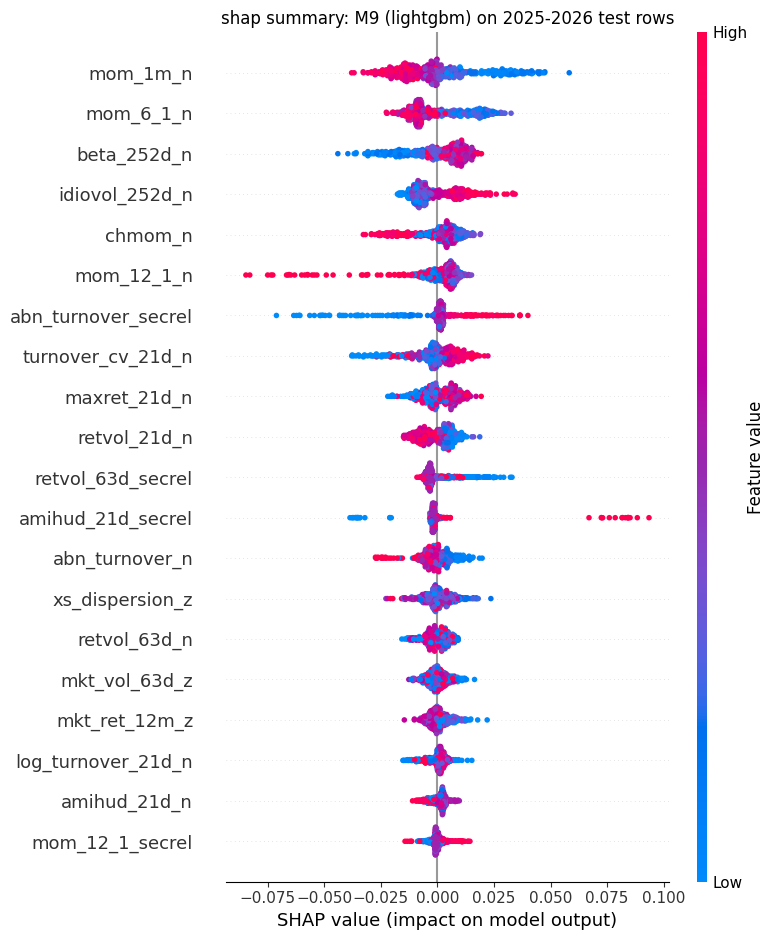

In [14]:
# summary plot (chart 14)
plt.figure()
shap.summary_plot(shap_values.values, shap_x, show=False, max_display=20)
plt.title("shap summary: M9 (lightgbm) on 2025-2026 test rows")
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "14_shap_summary_m9.png", dpi=150)
plt.show()

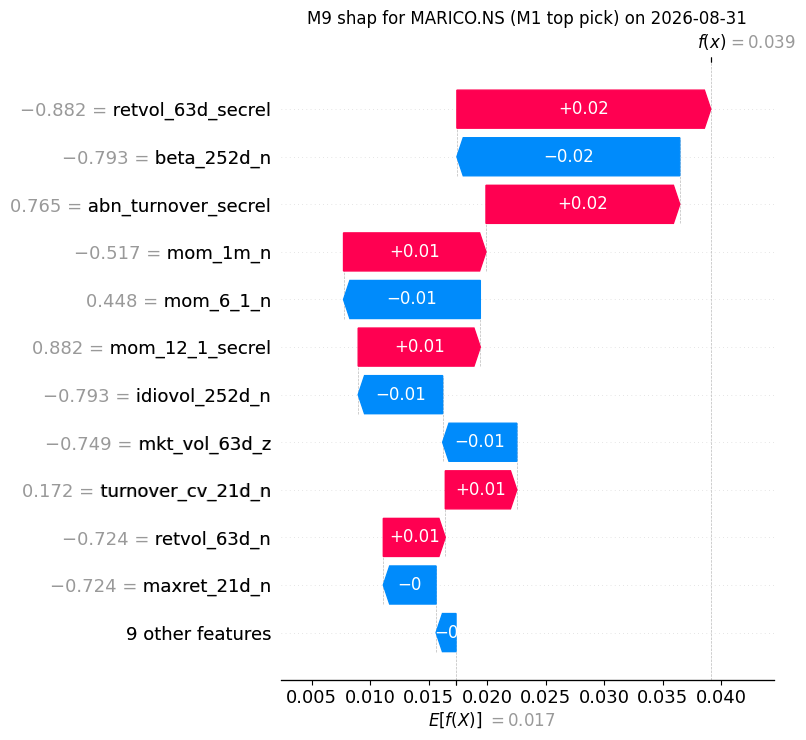

MARICO.NS | M1 rank: 1 | M9 rank: 10 of 30
M9 biggest pushes down: [('beta_252d_n', -0.0191), ('mom_6_1_n', -0.0117), ('idiovol_252d_n', -0.0072)]
M9 biggest pushes up:   [('mom_1m_n', 0.0122), ('abn_turnover_secrel', 0.0166), ('retvol_63d_secrel', 0.0217)]


In [15]:
# waterfall for the stock M1 ranks first on the latest date (chart 15), explained by M9
top1_ticker = latest_rows.loc[0, "Ticker"]
top1_features = latest_rows[latest_rows["Ticker"] == top1_ticker][tree_cols]
top1_explanation = explainer(top1_features)

plt.figure()
shap.plots.waterfall(top1_explanation[0], max_display=12, show=False)
plt.title("M9 shap for " + top1_ticker + " (M1 top pick) on " + str(latest_date.date()))
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "15_shap_waterfall_m1_top1_m9.png", dpi=150, bbox_inches="tight")
plt.show()

# where does M9 rank that stock among the 30?
latest_rows["m9_score"] = m9_model.predict(latest_rows[tree_cols])
m9_rank = latest_rows["m9_score"].rank(ascending=False)
print(top1_ticker, "| M1 rank: 1 | M9 rank:", int(m9_rank[latest_rows["Ticker"] == top1_ticker].iloc[0]), "of 30")

# biggest pushes up and down for this stock in words
top1_shap = pd.Series(top1_explanation.values[0], index=tree_cols).sort_values()
print("M9 biggest pushes down:", [(name, round(value, 4)) for name, value in top1_shap.head(3).items()])
print("M9 biggest pushes up:  ", [(name, round(value, 4)) for name, value in top1_shap.tail(3).items()])

## Part D: failure analysis of M1 (descriptive only, not used for selection)

In [16]:
# M1 scores for every out-of-sample labelled month: 2021-2024 (walk-forward period) + 2025-2026 (test)
oos_df = df_all[(df_all["Date"] >= pd.Timestamp("2021-01-01")) & df_all["has_label_1m"]].copy()
oos_df["score"] = m1_fit_predict(empty_train, oos_df, frozen["feature_cols"], {})

oos_ic = rank_ic_by_date(oos_df, "score")

# market state on each date (one value per date, all known at the decision date)
state_columns = ["Date", "mkt_ret_1m", "mkt_vol_63d", "xs_dispersion"]
market_state = model_table[state_columns].drop_duplicates("Date").set_index("Date")
ic_table = pd.DataFrame({"ic": oos_ic})
ic_table = ic_table.join(market_state)

print("out-of-sample months:", len(ic_table), "| from", ic_table.index.min().date(), "to", ic_table.index.max().date())
print("overall mean ic:", round(ic_table["ic"].mean(), 4))
print("nans in market state:", ic_table[["mkt_ret_1m", "mkt_vol_63d", "xs_dispersion"]].isna().sum().sum())

out-of-sample months: 67 | from 2021-01-29 to 2026-07-31
overall mean ic: -0.0134
nans in market state: 0


In [17]:
# split months by regime. medians are taken over these same months (descriptive only)
vol_median = ic_table["mkt_vol_63d"].median()
dispersion_median = ic_table["xs_dispersion"].median()

regimes = [
    ("high market volatility (mkt_vol_63d > median)", ic_table["mkt_vol_63d"] > vol_median),
    ("low market volatility (mkt_vol_63d <= median)", ic_table["mkt_vol_63d"] <= vol_median),
    ("up market (mkt_ret_1m > 0)", ic_table["mkt_ret_1m"] > 0),
    ("down market (mkt_ret_1m < 0)", ic_table["mkt_ret_1m"] < 0),
    ("high dispersion (xs_dispersion > median)", ic_table["xs_dispersion"] > dispersion_median),
    ("low dispersion (xs_dispersion <= median)", ic_table["xs_dispersion"] <= dispersion_median),
]

regime_rows = []
for regime_name, mask in regimes:
    regime_ic = ic_table.loc[mask, "ic"]
    regime_rows.append({
        "regime": regime_name,
        "months": len(regime_ic),
        "mean_ic": regime_ic.mean(),
        "std_ic": regime_ic.std(),
        "pct_positive": (regime_ic > 0).mean() * 100,
    })

regime_table = pd.DataFrame(regime_rows)
print("vol median:", round(vol_median, 4), "| dispersion median:", round(dispersion_median, 4))
print()
print("M1 mean rank ic by market regime (2021-2026, 67 months):")
print(regime_table.round(4).to_string(index=False))

vol median: 0.0079 | dispersion median: 0.0655

M1 mean rank ic by market regime (2021-2026, 67 months):
                                       regime  months  mean_ic  std_ic  pct_positive
high market volatility (mkt_vol_63d > median)      33   0.0262  0.2886       51.5152
low market volatility (mkt_vol_63d <= median)      34  -0.0519  0.2475       50.0000
                   up market (mkt_ret_1m > 0)      48  -0.0282  0.2919       50.0000
                 down market (mkt_ret_1m < 0)      19   0.0240  0.2035       52.6316
     high dispersion (xs_dispersion > median)      33  -0.0044  0.2743       51.5152
     low dispersion (xs_dispersion <= median)      34  -0.0221  0.2683       50.0000


In [18]:
# the 5 worst months and what the market looked like
worst_months = ic_table.sort_values("ic").head(5).copy()
worst_months["vol_regime"] = np.where(worst_months["mkt_vol_63d"] > vol_median, "high", "low")
worst_months["market"] = np.where(worst_months["mkt_ret_1m"] > 0, "up", "down")
worst_months["dispersion_regime"] = np.where(worst_months["xs_dispersion"] > dispersion_median, "high", "low")

print("5 worst months for M1 (ic, then market state at that date):")
print(worst_months.round(4).to_string())

5 worst months for M1 (ic, then market state at that date):
                ic  mkt_ret_1m  mkt_vol_63d  xs_dispersion vol_regime market dispersion_regime
Date                                                                                          
2023-06-30 -0.5409      0.0376       0.0051         0.0545        low     up               low
2024-03-28 -0.5309      0.0077       0.0080         0.0676       high     up              high
2025-10-31 -0.4982      0.0468       0.0059         0.0579        low     up               low
2021-01-29 -0.4968      0.0105       0.0109         0.0744       high     up              high
2025-05-30 -0.4549      0.0177       0.0115         0.0600       high     up               low


## Checks

In [19]:
check_results = {}

def report_check(name, passed):
    check_results[name] = passed
    if passed:
        print("PASS:", name)
    else:
        print("FAIL:", name)

In [20]:
# check 1: M1 as applied = M1 as frozen (same features, same signs, same scores)
same_model = frozen["chosen_model"] == "M1"
same_features = list(frozen["feature_cols"]) == list(COMPOSITE_PRIORS.keys())
same_signs = dict(frozen["composite_priors"]) == dict(COMPOSITE_PRIORS)

# recompute the score straight from the json file, without src/models.py
manual_score = np.zeros(len(test_df))
for feature in frozen["feature_cols"]:
    manual_score = manual_score + frozen["composite_priors"][feature] * test_df[feature].to_numpy()
manual_score = manual_score / len(frozen["feature_cols"])
same_scores = np.allclose(manual_score, test_df["score"].to_numpy(), rtol=0, atol=1e-12)

print("model name:", same_model, "| features:", same_features, "| signs:", same_signs, "| scores from json:", same_scores)
report_check("1. M1 settings identical to frozen_model.json (same features, same signs, same scores)",
             same_model and same_features and same_signs and same_scores)

model name: True | features: True | signs: True | scores from json: True
PASS: 1. M1 settings identical to frozen_model.json (same features, same signs, same scores)


In [21]:
# check 2: test ic only on dates >= 2025-01-31
test_ic_dates = m1_test_ic.index
print("first / last date in the test ic series:", test_ic_dates.min().date(), "/", test_ic_dates.max().date(),
      "| months:", len(test_ic_dates))
report_check("2. test ic uses only dates >= 2025-01-31 (19 months, last = 2026-07-31)",
             test_ic_dates.min() >= TEST_START and len(test_ic_dates) == 19 and test_ic_dates.max() == pd.Timestamp("2026-07-31")
             and test_df["Date"].min() >= TEST_START)

first / last date in the test ic series: 2025-01-31 / 2026-07-31 | months: 19
PASS: 2. test ic uses only dates >= 2025-01-31 (19 months, last = 2026-07-31)


In [22]:
# check 3: in every part B refit, training ends before the first prediction date
all_before = True
for i in range(len(refit_log)):
    if not refit_log.loc[i, "max_train_date"] < refit_log.loc[i, "min_predict_date"]:
        all_before = False

print("refits checked:", len(refit_log), "(3 models x 2 years)")
report_check("3. every part B refit has max train date < first prediction date", all_before and len(refit_log) == 6)

refits checked: 6 (3 models x 2 years)
PASS: 3. every part B refit has max train date < first prediction date


In [23]:
# check 4: contributions add up exactly to each stock's M1 score
exact_sum = np.allclose(contributions.sum(axis=1).to_numpy(), score_by_ticker.loc[contributions.index].to_numpy(), rtol=0, atol=1e-12)
print("largest gap over all 30 stocks:", (contributions.sum(axis=1) - score_by_ticker.loc[contributions.index]).abs().max())
report_check("4. M1 contributions sum exactly to each stock's M1 score (tolerance 1e-12)", exact_sum)

largest gap over all 30 stocks: 1.1102230246251565e-16
PASS: 4. M1 contributions sum exactly to each stock's M1 score (tolerance 1e-12)


In [24]:
# check 5: the latest-date picks use only features
label_columns = ["fwd_1m", "fwd_3m", "fwd_6m", "fwd_1m_rank", "has_label_1m", "y"]
labels_missing_on_latest_date = latest_rows["fwd_1m"].isna().all() and latest_rows["fwd_3m"].isna().all() \
                                and latest_rows["fwd_6m"].isna().all() and (not latest_rows["has_label_1m"].any())

used_columns = list(frozen["feature_cols"]) + list(tree_cols)
no_label_used = True
for column in used_columns:
    if column in label_columns:
        no_label_used = False

print("latest date:", latest_date.date(), "| labels missing for all 30 stocks:", labels_missing_on_latest_date)
print("label columns among the columns used for the picks and shap:", not no_label_used)
report_check("5. latest-date picks use only features (no labels exist for that date, none are used)",
             labels_missing_on_latest_date and no_label_used)

latest date: 2026-08-31 | labels missing for all 30 stocks: True
label columns among the columns used for the picks and shap: False
PASS: 5. latest-date picks use only features (no labels exist for that date, none are used)


## Charts

In [25]:
BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
GREY = "#8a8a86"

def style_axes(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, color="#e3e2de", linewidth=0.6)
    ax.set_axisbelow(True)

print("chart colors ready")

chart colors ready


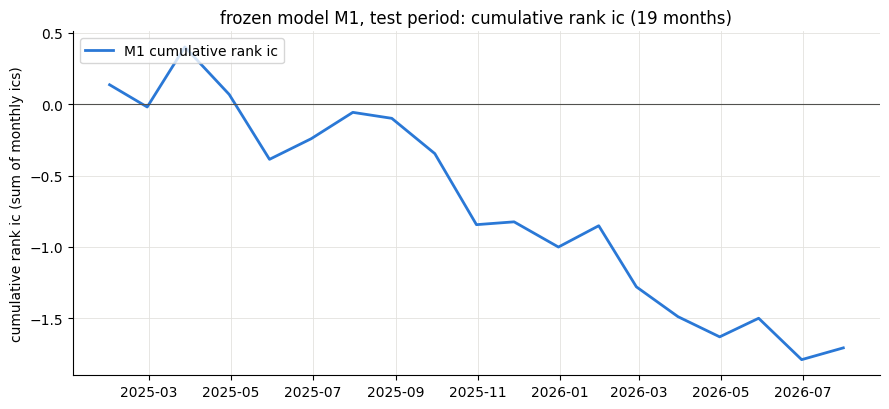

In [26]:
# chart 1: cumulative ic of M1 on the test months
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(m1_test_ic.index, m1_test_ic.cumsum(), color=BLUE, linewidth=2, label="M1 cumulative rank ic")
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_ylabel("cumulative rank ic (sum of monthly ics)")
ax.set_title("frozen model M1, test period: cumulative rank ic (19 months)")
ax.legend(loc="upper left")
style_axes(ax)
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "09_test_cumulative_ic_m1.png", dpi=150)
plt.show()

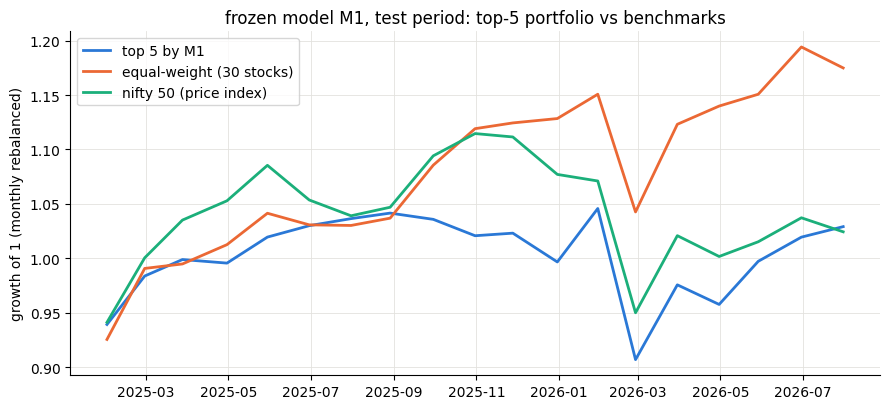

growth of 1 -> top 5: 1.029 | equal-weight: 1.175


In [27]:
# chart 2: top-5 of M1 vs equal-weight and nifty on the test months
test_top5 = top_k_returns(test_df, "score", 5)
test_dates = test_top5.index

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(test_dates, (1 + test_top5).cumprod(), color=BLUE, linewidth=2, label="top 5 by M1")
ax.plot(test_dates, (1 + benchmark_ew.loc[test_dates]).cumprod(), color=ORANGE, linewidth=2, label="equal-weight (30 stocks)")
if benchmark_nifty is not None:
    ax.plot(test_dates, (1 + benchmark_nifty.loc[test_dates]).cumprod(), color=AQUA, linewidth=2, label="nifty 50 (price index)")
ax.set_ylabel("growth of 1 (monthly rebalanced)")
ax.set_title("frozen model M1, test period: top-5 portfolio vs benchmarks")
ax.legend(loc="upper left")
style_axes(ax)
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "10_test_top5_vs_benchmarks.png", dpi=150)
plt.show()

print("growth of 1 -> top 5:", round((1 + test_top5).cumprod().iloc[-1], 3),
      "| equal-weight:", round((1 + benchmark_ew.loc[test_dates]).cumprod().iloc[-1], 3))

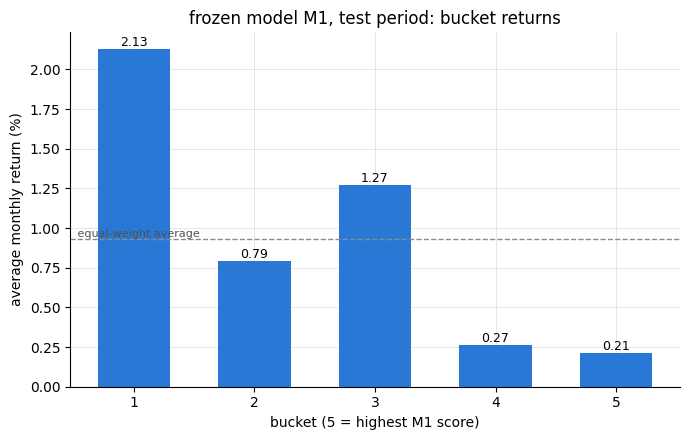

In [28]:
# chart 3: bucket returns of M1 on the test months
test_bucket_by_date, test_bucket_means = bucket_returns(test_df, "score")
test_ew_average = benchmark_ew.loc[test_df["Date"].unique()].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(test_bucket_means.index, test_bucket_means.values * 100, color=BLUE, width=0.6)
ax.axhline(test_ew_average, color=GREY, linestyle="--", linewidth=1)
ax.text(0.5, test_ew_average, " equal-weight average", va="bottom", ha="left", color="#52514e", fontsize=8)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), round(bar.get_height(), 2),
            ha="center", va="bottom", fontsize=9)
ax.set_xlabel("bucket (5 = highest M1 score)")
ax.set_ylabel("average monthly return (%)")
ax.set_title("frozen model M1, test period: bucket returns")
style_axes(ax)
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "11_test_bucket_returns_m1.png", dpi=150)
plt.show()

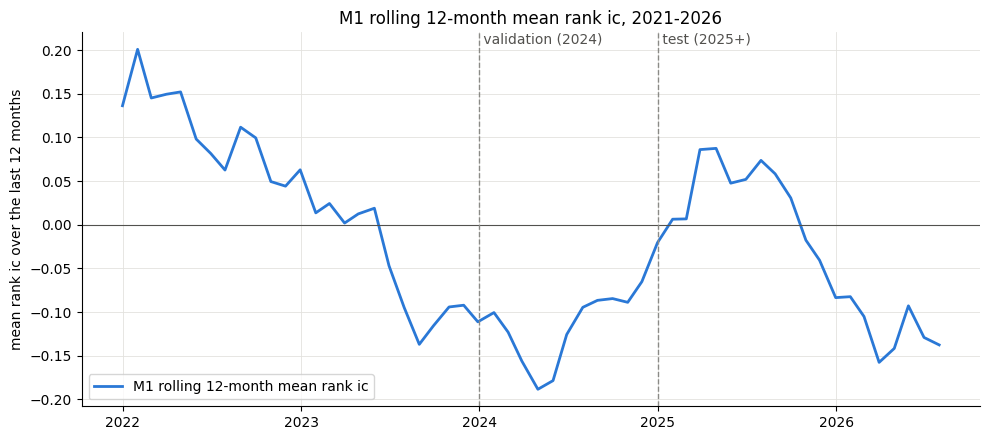

In [29]:
# chart 4: rolling 12-month mean ic of M1, 2021-2026
rolling_ic = ic_table["ic"].rolling(12, min_periods=12).mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rolling_ic.index, rolling_ic, color=BLUE, linewidth=2, label="M1 rolling 12-month mean rank ic")
ax.axhline(0, color="#52514e", linewidth=0.8)

validation_start = pd.Timestamp("2024-01-01")
test_start_line = pd.Timestamp("2025-01-01")
ax.axvline(validation_start, color=GREY, linestyle="--", linewidth=1)
ax.axvline(test_start_line, color=GREY, linestyle="--", linewidth=1)
top_of_axis = ax.get_ylim()[1]
ax.text(validation_start, top_of_axis, " validation (2024)", va="top", color="#52514e")
ax.text(test_start_line, top_of_axis, " test (2025+)", va="top", color="#52514e")
ax.set_ylabel("mean rank ic over the last 12 months")
ax.set_title("M1 rolling 12-month mean rank ic, 2021-2026")
ax.legend(loc="lower left")
style_axes(ax)
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "12_rolling_12m_ic_m1.png", dpi=150)
plt.show()

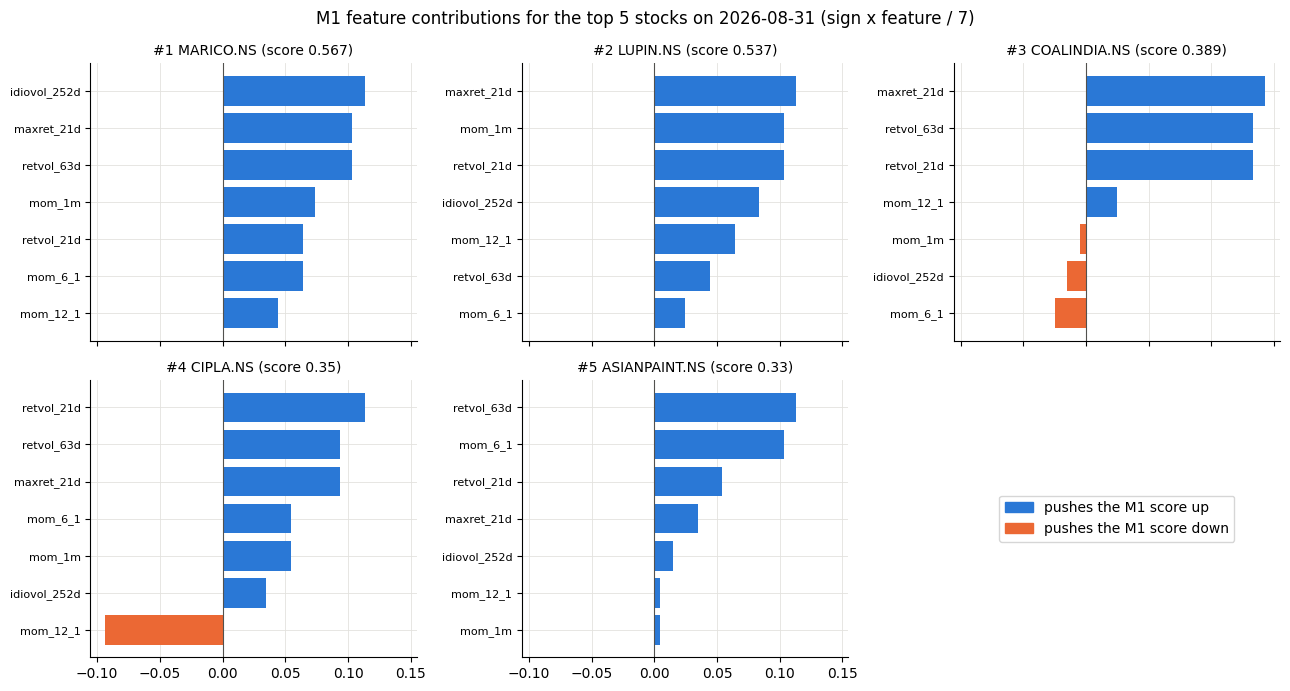

In [30]:
# chart 5: what drives the current top-5 picks (blue = pushes the M1 score up, orange = pushes it down)
top5_tickers = list(latest_rows["Ticker"].head(5))

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
axes_flat = axes.flatten()

for i in range(5):
    ticker = top5_tickers[i]
    sorted_contributions = contributions.loc[ticker].sort_values()
    bar_colors = []
    for value in sorted_contributions.values:
        if value > 0:
            bar_colors.append(BLUE)
        else:
            bar_colors.append(ORANGE)

    ax = axes_flat[i]
    ax.barh(range(len(sorted_contributions)), sorted_contributions.values, color=bar_colors)
    ax.set_yticks(range(len(sorted_contributions)))
    ax.set_yticklabels([name.replace("_n", "") for name in sorted_contributions.index], fontsize=8)
    ax.axvline(0, color="#52514e", linewidth=0.8)
    ax.set_title("#" + str(i + 1) + " " + ticker + " (score " + str(round(score_by_ticker[ticker], 3)) + ")", fontsize=10)
    style_axes(ax)

axes_flat[5].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
                    labels=["pushes the M1 score up", "pushes the M1 score down"], loc="center")
axes_flat[5].axis("off")
fig.suptitle("M1 feature contributions for the top 5 stocks on " + str(latest_date.date()) + " (sign x feature / 7)")
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "13_m1_contributions_top5.png", dpi=150)
plt.show()

## Summary

In [31]:
print("TEST HEADLINE")
print("frozen model M1 on unseen test data: mean ic =", round(m1_test_stats["mean_ic"], 4),
      "| 90% ci [", round(m1_test_stats["ic_ci_low"], 4), ",", round(m1_test_stats["ic_ci_high"], 4), "]",
      "| icir =", round(m1_test_stats["icir"], 3), "| t-stat =", round(m1_test_stats["t_stat"], 2),
      "| % positive months =", round(m1_test_stats["pct_positive"], 1), "| months =", m1_test_stats["n_months"])
print("top-5 excess vs equal-weight (monthly):", round(m1_test_stats["top5_excess_ew"], 4),
      "| vs nifty:", round(m1_test_stats["top5_excess_nifty"], 4),
      "| 3-month mean ic:", round(m1_test_stats["mean_ic_3m"], 4), "(" + str(m1_test_stats["n_months_3m"]) + " months)")
print()

print("COMPARISON ON TEST (M3, M7, M9 are post-hoc, not selected)")
print(all_models_table[["model", "status", "mean_ic", "ic_ci_low", "ic_ci_high", "icir", "top5_excess_ew",
                        "top5_excess_nifty", "mean_ic_3m"]].round(4).to_string(index=False))
print()

print("REGIME TABLE (M1 mean rank ic, 2021-2026)")
print(regime_table.round(4).to_string(index=False))
print()

print("CURRENT PICKS (M1, " + str(latest_date.date()) + ")")
for line in pick_lines:
    print(line)
print()

print("CHECK RESULTS")
for name in check_results:
    if check_results[name]:
        print("PASS:", name)
    else:
        print("FAIL:", name)
print("all checks passed:", all(check_results.values()))

TEST HEADLINE
frozen model M1 on unseen test data: mean ic = -0.0899 | 90% ci [ -0.1837 , 0.0035 ] | icir = -0.354 | t-stat = -1.54 | % positive months = 42.1 | months = 19
top-5 excess vs equal-weight (monthly): -0.0068 | vs nifty: 0.0003 | 3-month mean ic: 0.0002 (17 months)

COMPARISON ON TEST (M3, M7, M9 are post-hoc, not selected)
model                            status  mean_ic  ic_ci_low  ic_ci_high    icir  top5_excess_ew  top5_excess_nifty  mean_ic_3m
   M1                 SELECTED (frozen)  -0.0899    -0.1837      0.0035 -0.3542         -0.0068             0.0003      0.0002
   M3 post-hoc comparison, not selected   0.0512    -0.0206      0.1197  0.2567          0.0115             0.0186      0.0120
   M7 post-hoc comparison, not selected   0.0665    -0.0249      0.1496  0.2818          0.0018             0.0090      0.0736
   M9 post-hoc comparison, not selected   0.0607     0.0047      0.1161  0.3847          0.0018             0.0090      0.0138

REGIME TABLE (M1 mean rank